# <center> __Fisher Matrix__

\begin{split}
    F_{\alpha\beta} &\simeq \mu_{,\alpha}^T C^{-1} \mu_{,\beta} \\
    F_{\alpha\beta} &\simeq \frac{\partial\mu^T}{\partial \lambda_\alpha} (\Gamma_{\theta\theta', ijpq})^{-1} \frac{\partial\mu}{\partial \lambda_\beta}						
\end{split}

# Importing python modules

In [1]:
import numpy as np
import scipy as sc
from scipy.special import erf
import pandas as pd
from icecream import ic

#Get angular power spectrum for galaxy number counts and lensing
import camb
# from camb.sources import SplinedSourceWindow
# from camb import model

# Visualizing matrices
import matplotlib.pyplot as plt
# from matplotlib.colors import TwoSlopeNorm
# from matplotlib.colors import LogNorm
# from matplotlib.colors import SymLogNorm 
# from matplotlib.colors import LinearSegmentedColormap
# from matplotlib import ticker

# #Corner plot
# from matplotlib.gridspec import GridSpec
# import scipy.stats as stats

# Plots style
plt.rc('font',  size      = 12 )   # controls default text sizes
plt.rc('axes',  titlesize = 12 )   # fontsize of the axes title
plt.rc('xtick', labelsize = 12 )   # fontsize of the tick labels
plt.rc('ytick', labelsize = 12 )   # fontsize of the tick labels
plt.rc('legend',fontsize  = 12 )   # legend fontsize
plt.rc('axes',  labelsize = 14 )   # fontsize of the x and y labels
plt.rc('figure',titlesize = 16 )   # fontsize of the figure title

# **Functions** 

### Euclid - [Monatnari 2015](http://dx.doi.org/10.1088/1475-7516/2015/10/070)

In [2]:
# Montanari Euclid parameters
def pz_Euclid(z, z0):
    pz = z**2 * np.exp( -(z/z0)**(3/2) )
    return pz

def gal_bias_Euclid(z, b0=1):
    b_z = b0 * np.sqrt(1+z)
    del b0
    return b_z

def mag_bias_Euclid(z, s_0 = 0.1194, s_1 = 0.2122, s_2 = -0.0671, s_3 = 0.1031):
    s_z = s_0 + s_1*z + s_2*z**2 + s_3*z**3
    del s_0, s_1, s_2, s_3
    return np.round(s_z, 3)

z0_Euclid = 0.9/1.42      # z_mean = 0.9
N_gal_Euclid = 3.5*10**8  # galaxies / redshift / steradian

arr_z_central_Euclid = [0.14, 0.26, 0.39, 0.53, 0.69, 0.84, 1.0, 1.14, 1.3, 1.44]  # from  Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering


### DES initial parameters - [Fonseca 2016](https://academic.oup.com/mnras/article/466/3/2780/2679644)

In [3]:
#Set bins for DES

def pz_DES(z, z0=0.57):
    return (z/z0)**1.04*np.exp(-(z/z0)**1.34)  # arcmin**-2

def gal_bias_DES(z):
    return 1+0.84*z

def mag_bias_DES(z, s0=0.132, s1=0.259, s2=0.281, s3=0.691, s4=0.409, s5=0.152):
    s_z = s0 + s1*z - s2*z**2 + s3*z**3 - s4*z**4 + s5*z**5
    del s0, s1, s2, s3, s4, s5
    return s_z

z0_DES = 0.57
N_gal_DES      = 22.36 # galaxies / redshift / arcmin^2
N_gal_DES_deg2 = N_gal_DES * 1 / (1/60)**2   # galaxies / redshift * 1/deg^2
N_gal_DES_str  = N_gal_DES_deg2 * 1 / (np.pi/180)**2 #deg^2 to strd; galaxies / redshift * 1/strd
ic(N_gal_DES, N_gal_DES_deg2, N_gal_DES_str)


ic| N_gal_DES: 22.36
    N_gal_DES_deg2: 80496.0
    N_gal_DES_str: 264252779.95054534


(22.36, 80496.0, 264252779.95054534)

In [4]:
# #bins and bins details
# nbins=10
# zc=np.zeros(nbins)
# sz=np.zeros(nbins)
# cap=1/nbins

# z_int=np.arange(0.35,3.001,0.001)
# per_gal=np.zeros(len(z_int))
# tot_gal_overlap=quad(lambda x: func(x,amp_dndz_Sr,alpha, z0, beta),0.35,2.05)[0]
# for i in range(len(z_int)):
#     per_gal[i]=quad(lambda x: func(x,amp_dndz_Sr,alpha, z0, beta),0.35,z_int[i])[0]/tot_gal_overlap


# ## binning starts at z=0.35
# z_extremes=[0.35]
# pers=np.arange(cap,1.01,cap)
# for i in range(len(pers)):
#     z_extremes.append(z_int[np.argwhere(per_gal<pers[i])[-1][0]])
# #z_extremes.append(2.5)
# #print(z_extremes)

# for i in range(nbins):
#     zc[i]=round((z_extremes[i]+z_extremes[i+1])/2,3)
#     sz[i]=round((z_extremes[i+1]-z_extremes[i])/2,3)
    
# photo_z_uncertainty=np.around(0.05*(1+zc),3)
# print(zc)
# print(sz)
# print(photo_z_uncertainty)

# def W(z,zi,si,photo_z_uncertainty):
#     return (erf((zi+si-z)/(np.sqrt(2)*photo_z_uncertainty))-
#             erf((zi-si-z)/(np.sqrt(2)*photo_z_uncertainty)))/2


### LSST initial parameters - [LSST Collaboration](https://arxiv.org/abs/1809.01669)

__Y10__

We assume 10 tomographic bins spaced by 0.1 in photo-z between 0.2 ≤ z ≤ 1.2.

b(z) = 0.95/G(z)

G(z = 0) = 1

σz = 0.03(1 + z)

N_gal_LSST_Y10 = 48 # arcmin**-2

$$ dN/dz ∝ z² \exp [−(z/z0 )^α] $$
 
z0 = .28, alpha = 0.90

For Y10, they were [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943].

__Y1__

We assume 5 tomographic bins spaced by 0.2 in photo-z between 0.2 ≤ z ≤ 1.2.

N_gal_LSST_Y10 = 18 # arcmin**-2

(z0 , α) = (0.26, 0.94) 

For Y1, the per-bin bias values that were actually used were [1.562362, 1.732963, 1.913252, 2.100644, 2.293210]. 

In [5]:
sigma_val_LSST = 0.03


# Y10 - 10 redshit bins
def pz_LSST_Y10(z, z0):
    alpha = 0.90
    pz = z**2 * np.exp(-(z/z0)**(alpha) )
    return pz

z0_LSST_Y10 = 0.28
N_gal_LSST_Y10 = 48  # galaxies / redshift / arcmin^2
N_gal_LSST_Y10_str = N_gal_LSST_Y10 * 1 / (1/60)**2 * 1 / (np.pi/180)**2  # galaxies / redshift / str

arr_z_central_LSST_Y10 = np.arange(0.2, 1.2, 0.1)

arr_gal_bias_LSST_Y10 = np.array( [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943] )


# Y1 - 5 redshift bins
def pz_LSST_Y1(z, z0):
    alpha = 0.94
    pz = z**2 * np.exp(-(z/z0)**(alpha) )
    return pz

z0_LSST_Y1 = 0.26
N_gal_LSST_Y1 = 18  # galaxies / redshift / arcmin^-2
N_gal_LSST_Y1_str = N_gal_LSST_Y1 * 1 / (1/60)**2 * 1 / (np.pi/180)**2  # galaxies / redshift / str

arr_z_central_LSST_Y1 = np.arange(0.2, 1.2, 0.2)

arr_gal_bias_LSST_Y1 = np.array( [1.562362, 1.732963, 1.913252, 2.100644, 2.293210] )


#### Mag bias = ???

In [6]:


def bias(z,sample):
    if sample=='red':
        return 1+z
    if sample=='full':
        return 1+0.84*z
    else:
        return 0

### Importing my own functions

In [7]:
import sys
sys.path.insert(0, "/home/tiagosinde/Documents/Programar/Python_functions/")  # add Python_functions path to search list

# Creating and combining Redshift bins 
from Galaxy_Distribution import Window_func

# Calculate C_ell
from Calculate_C_ell_CAMB import C_ells_CAMB

# Fisher Covariance Matrix
from Fisher_Matrix_C_ell_w_theta import *


# **Fisher Matrix**  $w(\theta )$ vs $C_\ell$

## Initial parameters

In [8]:
# folder to save the data in
folder_name = "Fisher_Data/"

# Portion of the sky
f_sky = 1.00
# f_sky = 0.33
f_sky_str = str(round(f_sky, 2))[0] + str(round(f_sky, 2))[2:]


# Range of theta and ell values

theta_max = 90
# theta_max = 18

#coupled
l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] )
#decoupled
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +10
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +20


l_max = 1000

theta_min = 180/l_max


ic(theta_min, theta_max) 
ic(l_min, l_max)
ic(f_sky, f_sky_str)

ic| theta_min: 0.18, theta_max: 90
ic| l_min: np.int64(2), l_max: 1000
ic| f_sky: 1.0, f_sky_str: '10'


(1.0, '10')

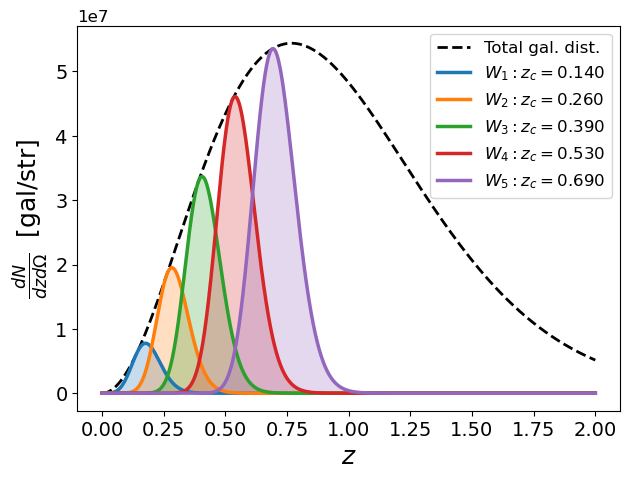

ic| N_thetas: 450


In [9]:
Survey = "Euclid"
# Survey = "DES"
# Survey = "LSST_Y1"
# Survey = "LSST_Y10"

N_bins = 5
# N_bins = 10

####################################### initial parameters ###############################################


if Survey == "Euclid":
    arr_z_central = arr_z_central_Euclid[0:N_bins]
elif Survey == "DES":
    arr_z_central = arr_z_central_DES[0:N_bins]
elif Survey == "LSST_Y1":
    arr_z_central = arr_z_central_LSST_Y1[0:N_bins]
elif Survey == "LSST_Y10":
    arr_z_central = arr_z_central_LSST_Y10[0:N_bins]



# # Creating central redshifts and redshift combinations
# z_ini = 0.3
# z_fini = 1.7
# bin_step = (z_fini - z_ini)/N_bins
# arr_z_central = np.arange(z_ini, z_fini, bin_step)

Data_arr_zs_auto= np.zeros((N_bins,2))
Data_arr_zs_full= np.zeros( (int(N_bins*(N_bins+1)/2), 2) )   # The number of elements in a triangular matrix of size n×n is given by the formula n(n+1)​/2
count = 0
for i in range(N_bins):
    z_c_i = arr_z_central[i]
    Data_arr_zs_auto[i] = np.array( [z_c_i, z_c_i] )
    for j in range(N_bins-i):
        z_c_j = arr_z_central[j]
        Data_arr_zs_full[count] = np.array( [z_c_i, z_c_j] )
        count+=1
del i, j, z_c_i, z_c_j, count



# Calculate Redshift bins
arr_zs = np.linspace(0, 2, 1000)
sigma_val = 0.05
arr_sigma_z = sigma_val*(1+arr_zs)

if Survey == "Euclid":
    dic_Window  = Window_func(arr_zs, arr_z_central, arr_sigma_z, z0_Euclid, N_gal_Euclid, 
                              func_pz=pz_Euclid, Show_WS=True, Fig_y_unit="gal/str")
elif Survey == "DES":
    dic_Window  = Window_func(arr_zs, arr_z_central, arr_sigma_z, z0_DES, N_gal_DES_str, 
                              func_pz=pz_DES, Show_WS=True, Fig_y_unit="gal/str")
elif Survey == "LSST_Y1":
    arr_sigma_z_LSST = sigma_val_LSST*(1+arr_zs)
    dic_Window  = Window_func(arr_zs, arr_z_central, arr_sigma_z_LSST, z0_LSST_Y1, N_gal_LSST_Y1_str, 
                              func_pz=pz_LSST_Y1, Show_WS=True, Fig_y_unit="gal/str")
elif Survey == "LSST_Y10":
    arr_sigma_z_LSST = sigma_val_LSST*(1+arr_zs)
    dic_Window  = Window_func(arr_zs, arr_z_central, arr_sigma_z_LSST, z0_LSST_Y10, N_gal_LSST_Y10_str, 
                              func_pz=pz_LSST_Y10, Show_WS=True, Fig_y_unit="gal/str")


########################################################## Mask similar to Euclid #############################
theta_val = theta_min
theta_step = 0.2
N_thetas = int((theta_max - theta_min)/theta_step) +1
ic(N_thetas)
thetas = np.empty( N_thetas )
count=0
while theta_val < theta_max:
    thetas[count] = theta_val
    theta_val += theta_step
    count+=1

full_l_min = 2
full_l_max = 1000
ells = np.arange(full_l_min, full_l_max+1, 1)

Pol_Legend = np.zeros( (N_thetas, len(ells))  )
for index_t, teta in enumerate(thetas):
    for index_l, l in enumerate(ells):
        Pol_Legend[index_t,index_l] = sc.special.lpmv(0, l, np.cos( np.radians(teta) ))

## Comological parameters + $\beta$ or + $s(z)$

I calculate the Cov Matrix and the derivatives of $C_\ell$ once, for the entirety of the $\ell$ range.

Afterwards, if we want to remove some of that $\ell s$ we can still use the original matrix, since the functions select the relevant data.

**Note:** even if we want to cut some $\theta s$ out of our analysis, $w(\theta)$ still needs the entire CovM of $C_\ell$ as input.

#### Test for beta

In [10]:
# dic_Cosm_param={"parameter_name" : ["par_info", fiducial_value, h_value]
dic_Cosm_param= {
                  'beta'      : ['beta'         , 1               , 10**-2    ],
                  "H0"        : ['hubble_const' , 67.27           , 0.7       ],    # H = 100 h    km s-1 Mpc-1
                  'w'         : ['w'            , -1              , 0.05      ],
                  'Ob'        : ['omega_baryon' , 0.0492          , 10**-4    ],
                  'Ocdm'      : ['omega_cdm'    , 0.2647          , 10**-3    ], 
                  "As"        : ["curv_amp"     , 2.2065          , 10**-2    ],    # comoving curvature power at k=pivot_scalar
                  "ns"        : ["spec_index"   , 0.9645          , 10**-2    ]     # scalar spectral index
                  }


#### String name to save file
save_filename = f"{Survey}_{N_bins}zbins_beta"

In [10]:
print(f"{folder_name}_..._{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}")

Fisher_Data/_..._Euclid_5zbins_beta_f10_lmin2_thetaMax90


#### Test for Magnification bias, s(z)

In [11]:
# if Survey == "Euclid":
#     save_filename = "Euclid_5zbins_sz"  # String name to save file
#     dic_Cosm_param= {  
#                       "s_1"       : ["mag_bias"     , mag_bias_Euclid(arr_z_central[0]) , 10**-3    ],
#                       "s_2"       : ["mag_bias"     , mag_bias_Euclid(arr_z_central[1]) , 10**-3    ], 
#                       "s_3"       : ["mag_bias"     , mag_bias_Euclid(arr_z_central[2]) , 10**-3    ], 
#                       "s_4"       : ["mag_bias"     , mag_bias_Euclid(arr_z_central[3]) , 10**-3    ], 
#                       "s_5"       : ["mag_bias"     , mag_bias_Euclid(arr_z_central[4]) , 10**-3    ], 
#                       "H0"        : ['hubble_const' , 67.27           , 0.7       ],    # H = 100 h    km s-1 Mpc-1
#                       'w'         : ['w'            , -1              , 0.05      ],
#                       'Ob'        : ['omega_baryon' , 0.0492          , 10**-4    ],
#                       'Ocdm'      : ['omega_cdm'    , 0.2647          , 10**-3    ], 
#                       "As"        : ["curv_amp"     , 2.2065          , 10**-2    ],    # comoving curvature power at k=pivot_scalar
#                       "ns"        : ["spec_index"   , 0.9645          , 10**-2    ]     # scalar spectral index
#                       }
# #     save_filename = "Euclid_10zbins_sz"


# save_filename = f"{Survey}_{N_bins}zbins_sz"

In [12]:
print(f"{folder_name}_..._{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}")

Fisher_Data/_..._Euclid_5zbins_beta_f10_lmin2_thetaMax90


#### Cosmology and Magnification bias values

In [13]:
############################# Cosmological parameters ####################################

dic_cosmology = {
    'Omega_M': dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1], 
    'Omega_b': dic_Cosm_param["Ob"][1],
    "Omega_cdm" : dic_Cosm_param["Ocdm"][1],
    'Omega_L': 1-(dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1]),
    "H_0":dic_Cosm_param["H0"][1],  
    'h': dic_Cosm_param["H0"][1]/100,
    'w': dic_Cosm_param["w"][1],
    "A_s": dic_Cosm_param["As"][1] *10**-9,
    'n_s': dic_Cosm_param["ns"][1],
    'sigma_8': 0.8
    }


pars = camb.CAMBparams()
pars.set_cosmology(H0=dic_cosmology["H_0"], 
                ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
pars.set_dark_energy( w=dic_cosmology["w"] )
pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])


# Magnification bias values, s(z)
dic_mag_bias = {}
z_count = 0
for key in (dic_Cosm_param.keys()):
    if dic_Cosm_param[key][0] == "mag_bias": 
        dic_mag_bias[arr_z_central[z_count]] = dic_Cosm_param[key][1]
        z_count+=1
if dic_mag_bias == {} and Survey=="Euclid":
    for z_c in arr_z_central:
        dic_mag_bias[z_c] = mag_bias_Euclid(z_c)
elif dic_mag_bias == {} and Survey=="DES":
    for z_c in arr_z_central:
        dic_mag_bias[z_c] = mag_bias_DES(z_c)
ic(dic_mag_bias)

ic| dic_mag_bias: {0.14: np.float64(0.148),
                   0.26: np.float64(0.172),
                   0.39: np.float64(0.198),
                   0.53: np.float64(0.228),
                   0.69: np.float64(0.268)}


{0.14: np.float64(0.148),
 0.26: np.float64(0.172),
 0.39: np.float64(0.198),
 0.53: np.float64(0.228),
 0.69: np.float64(0.268)}

### 1. Auto Correlations

#### Calculating Covriance Matrix and derivatives

In [14]:
############################# Calculating Covariant Matrix
if Survey == "Euclid":
    Cov_Matrix_auto = Fisher_CovM(Data_arr_zs_auto, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, 
                                  dic_mag_bias, C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_Euclid)
elif Survey == "DES":
    Cov_Matrix_auto = Fisher_CovM(Data_arr_zs_auto, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, 
                                  dic_mag_bias, C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_DES)

# Visualizing_Cov_Matrix(Data_arr_zs_auto, l_min, l_max, Cov_Matrix_auto)

Cov Matrix Calculated!


In [ ]:
################################## Calculating derivatives

dic_derivatives_auto = Fisher_derivative(Data_arr_zs_auto, arr_zs, dic_Window, full_l_min, full_l_max, dic_mag_bias, 
                                         dic_Cosm_param, C_ells_CAMB )
# Visualizing_derivatives( Data_arr_zs_auto, l_min, l_max, dic_Cosm_param, dic_derivatives_auto )

beta
H0
w
Ob
Ocdm
As
ns
Derivatives Calculated!


#### $C_\ell$ auto

ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(4995.0)
    N_data*N_ells: 4995


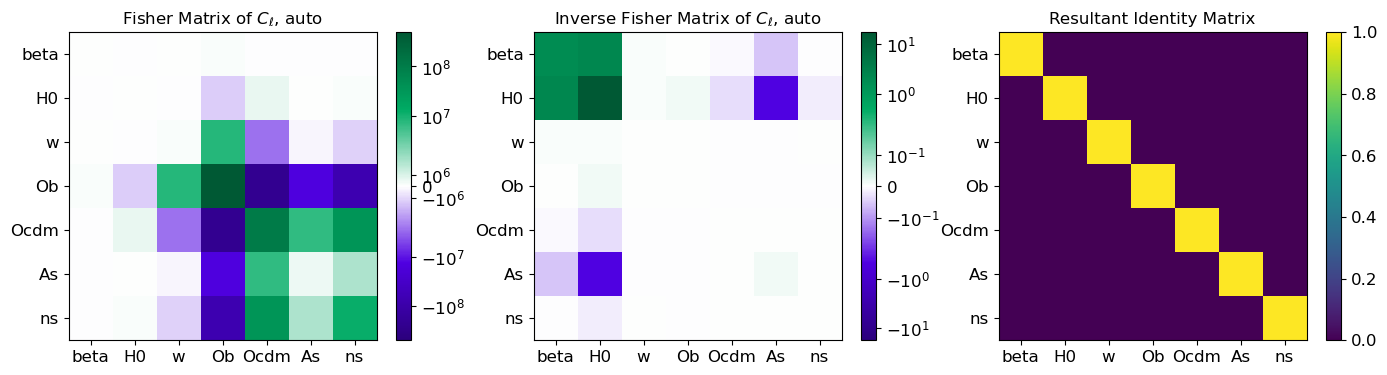

ic| np.sum(Matrix @ Matrix_inv): np.float64(6.99999999828071)


In [17]:
Fish_Cl_auto = Fisher_Matrix_Cl(Data_arr_zs_auto, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
                                full_l_min, l_min, full_l_max, l_max, f_sky)

Visualising_F_Matrices( Fish_Cl_auto, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $C_\ell$, auto",r"Inverse Fisher Matrix of $C_\ell$, auto",
                                    "Resultant Identity Matrix"])

# Saving data
df_Cl_auto = pd.DataFrame(data=Fish_Cl_auto.astype(float))
df_Cl_auto.to_csv(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                  sep=' ', header=False, float_format='%.8g', index=False)

#### $w(\theta)$ auto

ic| index_M: 1
ic| index_M: 6
ic| index_M: 11
ic| index_M: 16
ic| index_M: 21
ic| Big_Matrix.shape: (2250, 2250)
ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(2250.000000000061)
    N_data*N_thetas: 2250


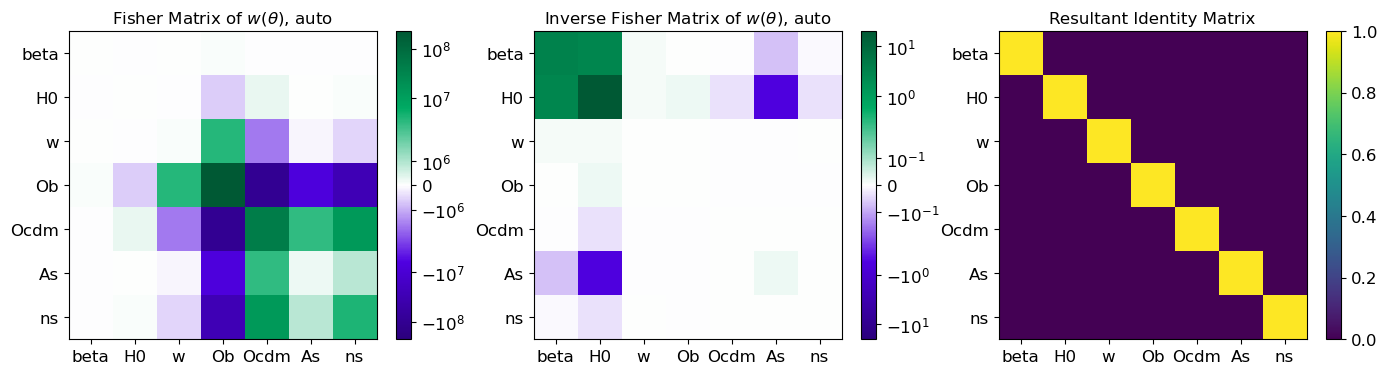

ic| np.sum(Matrix @ Matrix_inv): np.float64(7.000000000760117)


In [18]:
Fish_w_auto = Fisher_Matrix_w(Data_arr_zs_auto, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
                              f_sky)

Visualising_F_Matrices( Fish_w_auto, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, auto",r"Inverse Fisher Matrix of $w(\theta)$, auto",
                                    "Resultant Identity Matrix"])

# Saving data
df_w_auto = pd.DataFrame(data=Fish_w_auto.astype(float))
df_w_auto.to_csv(F"{folder_name}FisherM_w_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                 sep=' ', header=False, float_format='%.8g', index=False)

### 2. Full correlations (Auto+Cross)

#### Cov Matrix and derivatives 

In [14]:
pars = camb.CAMBparams()
pars.set_cosmology(H0=dic_cosmology["H_0"], 
                ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
pars.set_dark_energy( w=dic_cosmology["w"] )
pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])


############################# Calculating Covariant Matrix
if Survey == "Euclid":
    Cov_Matrix_full = Fisher_CovM(Data_arr_zs_full, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, dic_mag_bias, 
                                  C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_Euclid)
elif Survey == "DES":
    Cov_Matrix_full = Fisher_CovM(Data_arr_zs_full, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, dic_mag_bias, 
                                  C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_DES)


# Visualizing_Cov_Matrix(Data_arr_zs_full, l_min, l_max, Cov_Matrix_full, fig_size=(10,8) )

Cov Matrix Calculated!


In [40]:
# # Saving data
# df_CovM_full = pd.DataFrame(data=Cov_Matrix_full.astype(float))
# df_CovM_full.to_csv(F"{folder_name}FisherM_CovM_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", sep=' ', header=False, float_format='%.8g', index=False)

In [15]:
################################## Calculating derivatives

dic_derivatives_full = Fisher_derivative(Data_arr_zs_full, arr_zs, dic_Window, full_l_min, full_l_max, dic_mag_bias, 
                                         dic_Cosm_param, C_ells_CAMB )

# Visualizing_derivatives( Data_arr_zs_cross, l_min, l_max, dic_Cosm_param, dic_derivatives_cross, 
#                         aspect_val=1/1500, fig_size=(20,8) )

beta
H0
w
Ob
Ocdm
As
ns
Derivatives Calculated!


#### $C_\ell$ full

In [16]:
Fish_Cl_full = Fisher_Matrix_Cl(Data_arr_zs_full, dic_Cosm_param, Cov_Matrix_full, dic_derivatives_full, 
                                 full_l_min, l_min, full_l_max, l_max, f_sky)

Visualising_F_Matrices( Fish_Cl_full, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $C_\ell$, full",r"Inverse Fisher Matrix of $C_\ell$, full",
                                    "Resultant Identity Matrix"])

# Saving data
df_Cl_full = pd.DataFrame(data=Fish_Cl_full.astype(float))
df_Cl_full.to_csv(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                  sep=' ', header=False, float_format='%.8g', index=False)

LinAlgError: Singular matrix

#### $w(\theta)$ full

ic| index_M: 1
ic| index_M: 46
ic| index_M: 91
ic| index_M: 136
ic| index_M: 181
ic| Big_Matrix.shape: (6750, 6750)
ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(6750.0)
    N_data*N_thetas: 6750


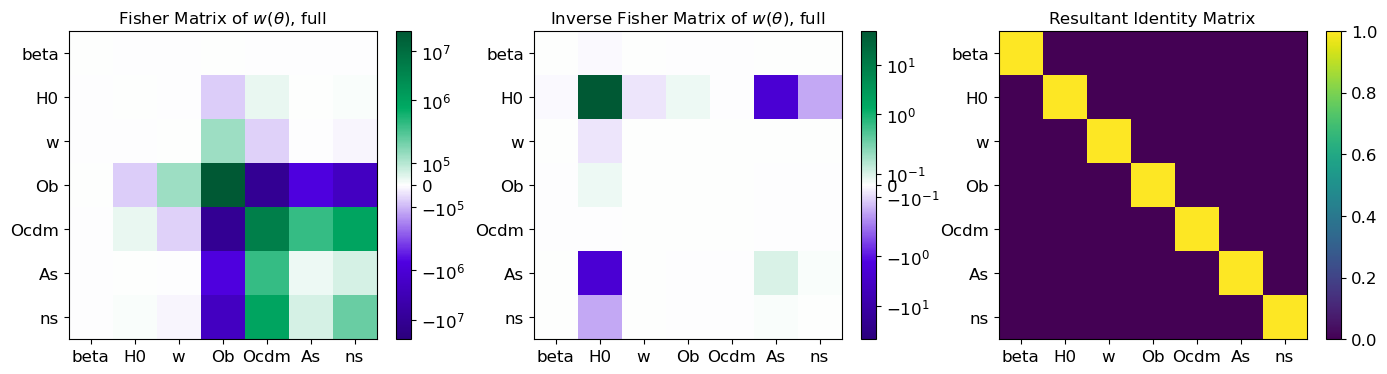

ic| np.sum(Matrix @ Matrix_inv): np.float64(6.999999999961647)


In [ ]:
Fish_w_full = Fisher_Matrix_w(Data_arr_zs_full, ells, thetas, Pol_Legend,  dic_Cosm_param, Cov_Matrix_full, dic_derivatives_full, f_sky)

Visualising_F_Matrices( Fish_w_full, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, full",r"Inverse Fisher Matrix of $w(\theta)$, full",
                                    "Resultant Identity Matrix"])

# Saving data
df_w_full = pd.DataFrame(data=Fish_w_full.astype(float))
df_w_full.to_csv(F"{folder_name}FisherM_w_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", sep=' ', header=False, float_format='%.8g', index=False)

### 3. Visualise Corner plots 

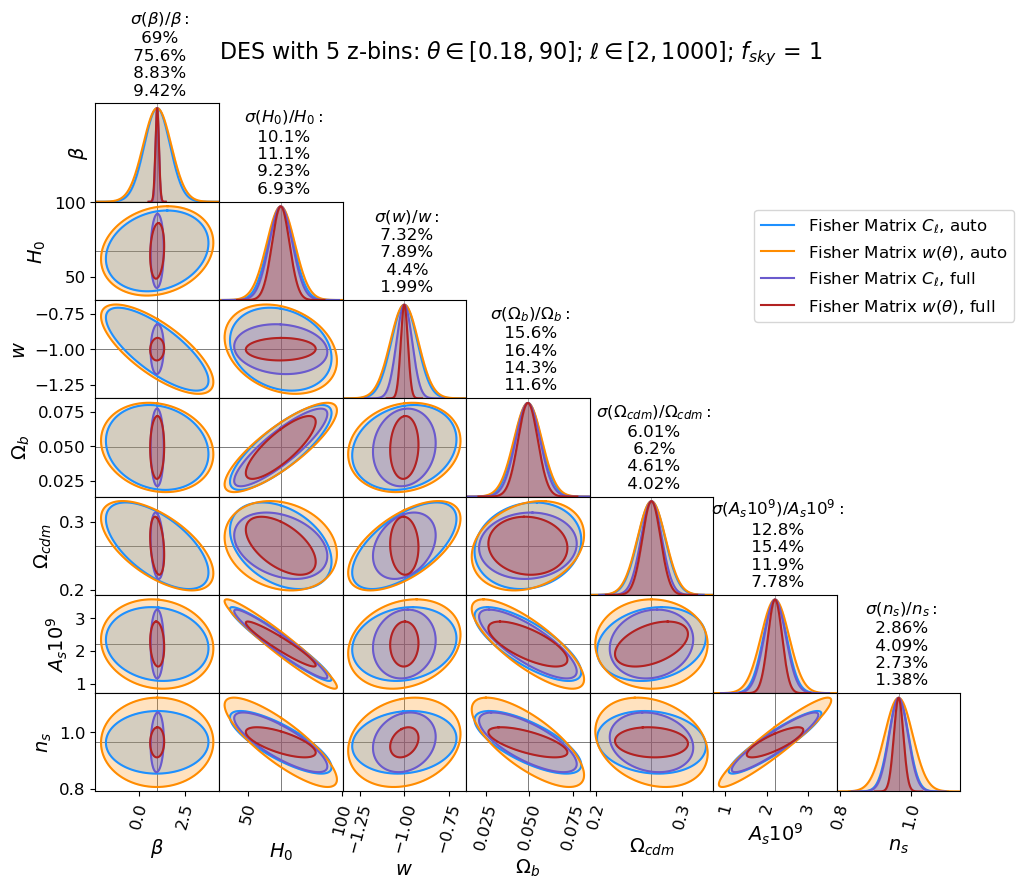

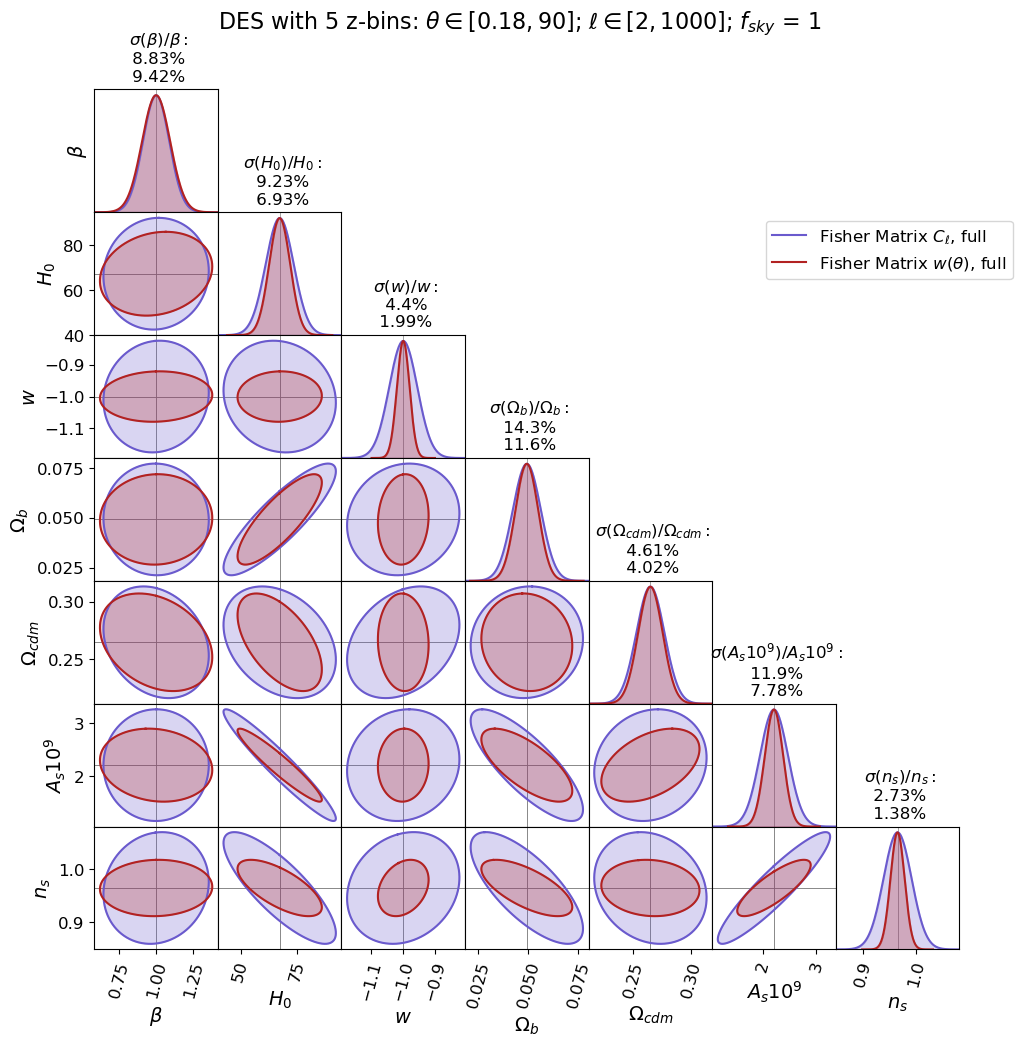

In [30]:
# Importing Fihser Matrices values from  saved data

f_sky, f_sky_str = 1, 10
l_min     = 2
theta_max = 90

FIM_Cl_auto  = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto   = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{  save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_Cl_cross = np.loadtxt(open(F"{folder_name}FisherM_Cl_cross_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_cross  = np.loadtxt(open(F"{folder_name}FisherM_w_cross_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_cross = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)

########################## Corner plots ###################################################################

fid=[]
# counter = 1
for key in dic_Cosm_param.keys():
    fid.append( dic_Cosm_param[key][1] )
    # if counter > 4:
    #     fid.append( dic_Cosm_param[key][1] )
    # counter+=1

par = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]
par_titles = par

# Plot_title = r"$f_{sky}$ = " + rf"{f_sky:.3g}; $z_c = {z_1, z_2, z_3, z_4 }$; $\sigma_z = {sigma_val}$"
# Plot_title = rf"Error Ellipses: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"
Plot_title = rf"{Survey} with {N_bins} z-bins: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"

# list_colors = ["#37b67e", "#057041", "#7e71bf", "#4900ac"]
list_colors = ["dodgerblue", "darkorange", "slateblue", "firebrick"]


# Only s(z)
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [0:4,0:4]) ]

# Only Cosm param
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [4:,4:]) ]

Fishers = [ FIM_Cl_auto, FIM_w_auto, FIM_Cl_cross, FIM_w_cross ]
Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto", r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=list_colors, figure_size=(10,8) )

# Fishers = [ FIM_Cl_auto, FIM_w_auto]
# Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto"  ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title,  Flabels=Flabels, cores=[list_colors[0], list_colors[2]] )

Fishers = [ FIM_Cl_cross, FIM_w_cross ]
Flabels = [ r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=[list_colors[2], list_colors[3]] )

### 4. Compare performance with histograms

#### Baseline

ic| list_parameters: ['$\\beta$',
                      '$H_0$',
                      '$w$',
                      '$\\Omega_b$',
                      '$\\Omega_{cdm}$',
                      '$A_s 10^{9}$',
                      '$n_s$']
    check_parameters: ['beta', 'H0', 'w', 'Ob', 'Ocdm', 'As', 'ns']


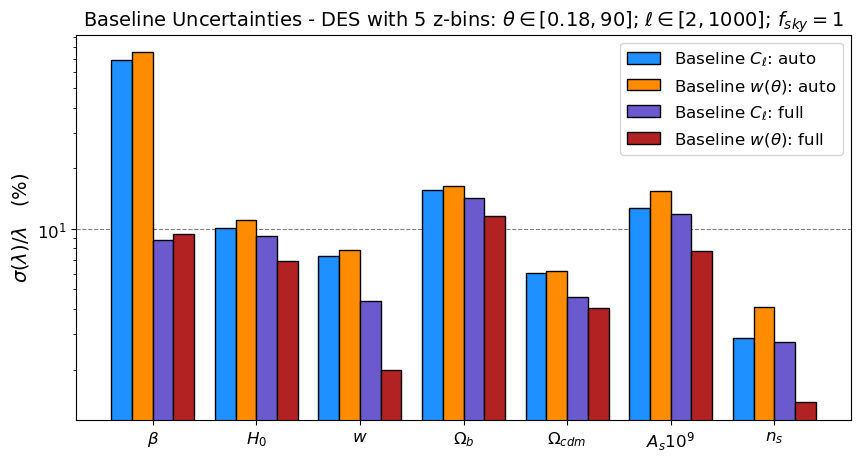

In [31]:
FIM_Cl_auto_Base  = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto_Base   = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{  save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_Cl_cross_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_cross_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_cross_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_cross_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_cross_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)

Inv_FIM_Cl_auto_Base = np.linalg.inv( FIM_Cl_auto_Base )
Inv_FIM_w_auto_Base  = np.linalg.inv( FIM_w_auto_Base  )    
Inv_FIM_Cl_full_Base = np.linalg.inv( FIM_Cl_cross_Base)  
Inv_FIM_w_full_Base  = np.linalg.inv( FIM_w_cross_Base )  

Title_plot = rf"Baseline Uncertainties - {Survey} with {N_bins} z-bins: $\theta \in [{0.18}, {90}]$; $\ell \in [{2}, {1000}]$; " + r"$f_{sky} = 1$"  
# Title_plot = r"Baseline Uncertainties: Set $\beta$"  

list_parameters = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )

ic(list_parameters, check_parameters)



Est_Result_dic_Base = { }

array_Cl_auto_Base = np.zeros( len(list_parameters) )
array_w_auto_Base  = np.zeros( len(list_parameters) )
array_Cl_full_Base = np.zeros( len(list_parameters) )
array_w_full_Base  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    array_Cl_auto_Base[index_p] = np.sqrt( Inv_FIM_Cl_auto_Base [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    array_w_auto_Base[index_p]  = np.sqrt( Inv_FIM_w_auto_Base [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full_Base[index_p] = np.sqrt( Inv_FIM_Cl_full_Base [index_p,index_p] ) / np.abs(p) * 100
    array_w_full_Base[index_p]  = np.sqrt( Inv_FIM_w_full_Base [index_p,index_p] )  / np.abs(p) * 100


Est_Result_dic_Base[r"Baseline $C_\ell$: auto"]    = array_Cl_auto_Base
Est_Result_dic_Base[r"Baseline $w(\theta)$: auto"]= array_w_auto_Base
Est_Result_dic_Base[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys= []
for key in Est_Result_dic_Base.keys():
    list_Base_keys.append(key)

width=0.2
Label_loc = np.arange(len(list_parameters))
# arr_colors = ['#249140', '#244591', '#5d2491', '#24917d']


fig, ax = plt.subplots(figsize=(10,5))

counter = 0
for key in list_Base_keys:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base[key], width, label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
plt.legend()

ax.set_axisbelow(True)
ax.yaxis.grid(color='gray', linestyle='dashed')

plt.show()

#### Parameters to compare Baseline with

In [32]:
f_sky, f_sky_str = 0.33, "033"
theta_max = 18
l_min     = 10


FIM_Cl_auto  = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto   = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{  save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_cross = np.loadtxt(open(F"{folder_name}FisherM_Cl_cross_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_cross  = np.loadtxt(open(F"{folder_name}FisherM_w_cross_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)

Inv_FIM_Cl_auto = np.linalg.inv( FIM_Cl_auto )
Inv_FIM_w_auto  = np.linalg.inv( FIM_w_auto  )    
Inv_FIM_Cl_full = np.linalg.inv( FIM_Cl_cross)  
Inv_FIM_w_full  = np.linalg.inv( FIM_w_cross )  


Title_plot = rf"Increase between Baseline and model: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"  
# Title_plot = rf"Parameter's Uncertainties: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"  
# Title_plot = r"Baseline Uncertainties: Set $\beta$"  

list_parameters = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )

ic(list_parameters, check_parameters)



Est_Result_dic = { }

array_Cl_auto = np.zeros( len(list_parameters) )
array_w_auto  = np.zeros( len(list_parameters) )
array_Cl_full = np.zeros( len(list_parameters) )
array_w_full  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    array_Cl_auto[index_p] = np.sqrt( Inv_FIM_Cl_auto [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    array_w_auto[index_p]  = np.sqrt( Inv_FIM_w_auto [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full[index_p] = np.sqrt( Inv_FIM_Cl_full [index_p,index_p] ) / np.abs(p) * 100
    array_w_full[index_p]  = np.sqrt( Inv_FIM_w_full [index_p,index_p] )  / np.abs(p) * 100


Est_Result_dic[r"$C_\ell$: auto"]    = array_Cl_auto
Est_Result_dic[r"$w(\theta)$: auto"]= array_w_auto
Est_Result_dic[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic[r"$w(\theta)$: full"] = array_w_full


width=0.2
Label_loc = np.arange(len(list_parameters))
# arr_colors = ['#249140', '#244591', '#5d2491', '#24917d']

counter = 0
fig, ax = plt.subplots(figsize=(10,5))
for index_key, key in enumerate(Est_Result_dic.keys()):
    offset = width * counter
    # rects = ax.bar(Label_loc + offset, Cosm_param, width, label=Estimator, color=list_colors[counter])
    rects = ax.bar(Label_loc + offset, Est_Result_dic[key]-Est_Result_dic_Base[list_Base_keys[index_key]], width, label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

# counter = 0
# for Estimator, Cosm_param in Est_Result_dic_Base.items():
#     offset = width * counter
#     rects = ax.bar(Label_loc + offset, Cosm_param, width, label=Estimator, color=list_colors[counter], alpha=0.75, edgecolor="k")
#     counter += 1



ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='gray', linestyle='dashed')
plt.legend()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'Fisher_Data/FisherM_Cl_auto_DES_5zbins_beta_f033_lmin10_thetaMax18.csv'